In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import curve_fit

df = pd.read_csv("solar_system.csv")

print("Shape:", df.shape)
print("First five rows:")
print(df.head())
print("Last five rows:")
print(df.tail())
print("Columns:", df.columns)
print("Row names:", df.iloc[:, 0])

Shape: (20, 11)
First five rows:
                Attribute Mercury  Venus  Earth   Moon   Mars Jupiter  Saturn  \
0          Mass (10^24kg)   0.330   4.87   5.97  0.073  0.642    1898     568   
1           Diameter (km)    4879  12104  12756   3475   6792  142984  120536   
2        Density (kg/m^3)    5429   5243   5514   3340   3934    1326     687   
3         Gravity (m/s^2)     3.7    8.9    9.8    1.6    3.7    23.1     9.0   
4  Escape Velocity (km/s)     4.3   10.4   11.2    2.4    5.0    59.5    35.5   

  Uranus Neptune   Pluto  
0   86.8     102  0.0130  
1  51118   49528    2376  
2   1270    1638    1850  
3    8.7    11.0     0.7  
4   21.3    23.5     1.3  
Last five rows:
                  Attribute Mercury Venus Earth Moon  Mars  Jupiter   Saturn  \
15     Mean Temperature (C)     167   464    15  -20   -65     -110     -140   
16  Surface Pressure (bars)       0    92     1    0  0.01  Unknown  Unknown   
17          Number of Moons       0     0     1    0     2    

In [3]:
print(df["Attribute"].to_string())

0                  Mass (10^24kg)
1                   Diameter (km)
2                Density (kg/m^3)
3                 Gravity (m/s^2)
4          Escape Velocity (km/s)
5         Rotation Period (hours)
6           Length of Day (hours)
7     Distance from Sun (10^6 km)
8            Perihelion (10^6 km)
9              Aphelion (10^6 km)
10          Orbital Period (days)
11        Orbital Velocity (km/s)
12      Orbital Inclination (deg)
13           Orbital Eccentricity
14       Obliquity to Orbit (deg)
15           Mean Temperature (C)
16        Surface Pressure (bars)
17                Number of Moons
18                   Ring System?
19         Global Magnetic Field?


In [4]:
orbital_period = df.iloc[10, 1:].astype(float)
perihelion = df.iloc[8, 1:].astype(float)
aphelion = df.iloc[9, 1:].astype(float)

print("Orbital Period:")
print(orbital_period)

print("Perihelion:")
print(perihelion)

print("Aphelion:")
print(aphelion)

Orbital Period:
Mercury       88.0
Venus        224.7
Earth        365.2
Moon          27.3
Mars         687.0
Jupiter     4331.0
Saturn     10747.0
Uranus     30589.0
Neptune    59800.0
Pluto      90560.0
Name: 10, dtype: float64
Perihelion:
Mercury      46.000
Venus       107.500
Earth       147.100
Moon          0.363
Mars        206.700
Jupiter     740.600
Saturn     1357.600
Uranus     2732.700
Neptune    4471.100
Pluto      4436.800
Name: 8, dtype: float64
Aphelion:
Mercury      69.800
Venus       108.900
Earth       152.100
Moon          0.406
Mars        249.300
Jupiter     816.400
Saturn     1506.500
Uranus     3001.400
Neptune    4558.900
Pluto      7375.900
Name: 9, dtype: float64


Perihelion: The closest distance between a planet and the Sun.

Aphelion: The farthest distance between a planet and the Sun.

Semi-major axis: Half the longest diameter of an elliptical orbit.

In [5]:
semi_major_axis = (perihelion + aphelion) / 2

print(semi_major_axis)

Mercury      57.9000
Venus       108.2000
Earth       149.6000
Moon          0.3845
Mars        228.0000
Jupiter     778.5000
Saturn     1432.0500
Uranus     2867.0500
Neptune    4515.0000
Pluto      5906.3500
dtype: float64


In [6]:
new_row = pd.DataFrame(
    [["Semi-major Axis (10^6 km)"] + semi_major_axis.tolist()],
    columns=df.columns
)

df = pd.concat([df, new_row], ignore_index=True)

print("New shape:", df.shape)

New shape: (21, 11)


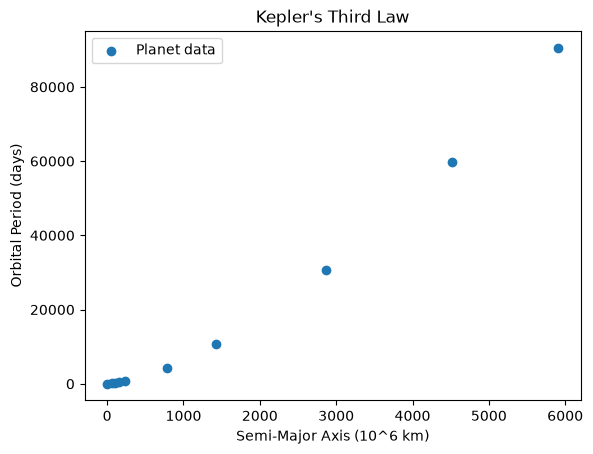

In [9]:
plt.scatter(semi_major_axis, orbital_period, label="Planet data")

plt.xlabel("Semi-Major Axis (10^6 km)")
plt.ylabel("Orbital Period (days)")
plt.title("Kepler's Third Law")
plt.legend()
plt.show()

In [8]:
def keplers_third_law(a, m):
    return m * a ** 1.5

In [10]:
# Exclude the Moon because it orbits Earth
a = semi_major_axis.drop("Moon")
T = orbital_period.drop("Moon")

popt, pcov = curve_fit(keplers_third_law, a, T)

m_fit = popt[0]

print(f"Fit: T = {m_fit:.2f} * a^1.5")

Fit: T = 0.20 * a^1.5


In [11]:
residuals = T - keplers_third_law(a, m_fit)

chi2 = np.sum(residuals**2)
dof = len(T) - len(popt)
chi2_reduced = chi2 / dof

print("Reduced chi-squared:", round(chi2_reduced, 2))

Reduced chi-squared: 46343.46


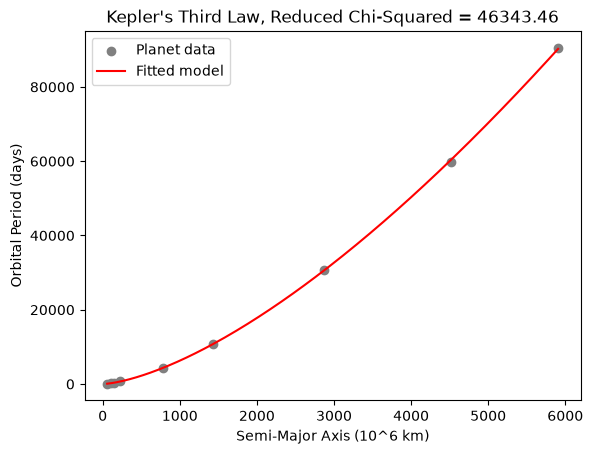

In [12]:
a_smooth = np.linspace(min(a), max(a), 200)

plt.scatter(a, T, color="gray", label="Planet data")

plt.plot(
    a_smooth,
    keplers_third_law(a_smooth, m_fit),
    color="red",
    label="Fitted model"
)

plt.xlabel("Semi-Major Axis (10^6 km)")
plt.ylabel("Orbital Period (days)")
plt.title(f"Kepler's Third Law, Reduced Chi-Squared = {chi2_reduced:.2f}")
plt.legend()
plt.show()

In [13]:
df.to_csv("kepler.csv", index=False)

print("Saved kepler.csv")

Saved kepler.csv
